In [1]:
data1 = read.csv("Sonda1.txt", sep = "\t", header = TRUE, dec = ",")
data2 = read.csv("Sonda2.txt", sep = "\t", header = TRUE, dec = ",")
data = rbind(data1, data2); data

deltaZ = 19.2
data$z = data$z+deltaZ

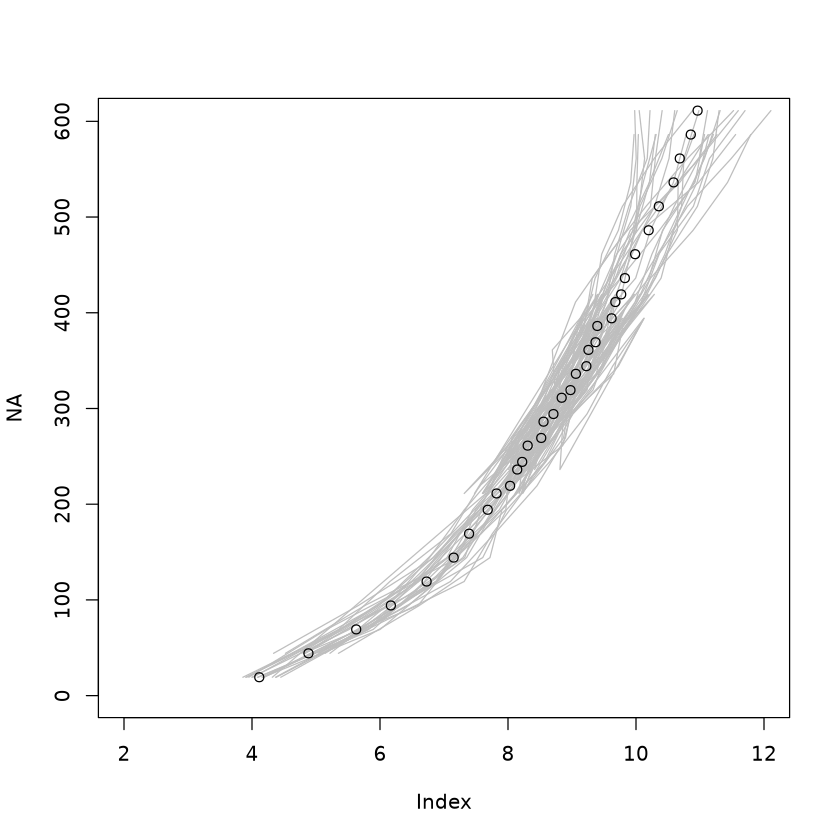

In [2]:
height = unique(data$y)
height

table16 = data[data$y == height[3],2:3]
table18 = data[data$y == height[2],2:3]
length(table18$z)

for (i in 4:length(height)) {
  plotd = data[data$y == height[i],3]
  if(length(plotd)==16){table16 = cbind(table16, plotd)}
  if(length(plotd)==18){table18 = cbind(table18, plotd)}
}

t16 = cbind(table16[1], rowMeans(table16[-1]))
colnames(t16) = c("z", "Umean")

t18 = cbind(table18[1], rowMeans(table18[-1]))
colnames(t18) = c("z", "Umean")


table = rbind(t16, t18)

tableMean = table[order(table$z, decreasing = FALSE), ]

plot(NA, xlim = c(2, 12), ylim = c(1,600))
for (i in 1:length(height)) {
  plotd = data #[order(data1$y),]
  plotd = plotd[plotd$y == height[i],]
  lines(plotd$Umean, plotd$z, col = "grey")
}
points(tableMean$Umean, tableMean$z)

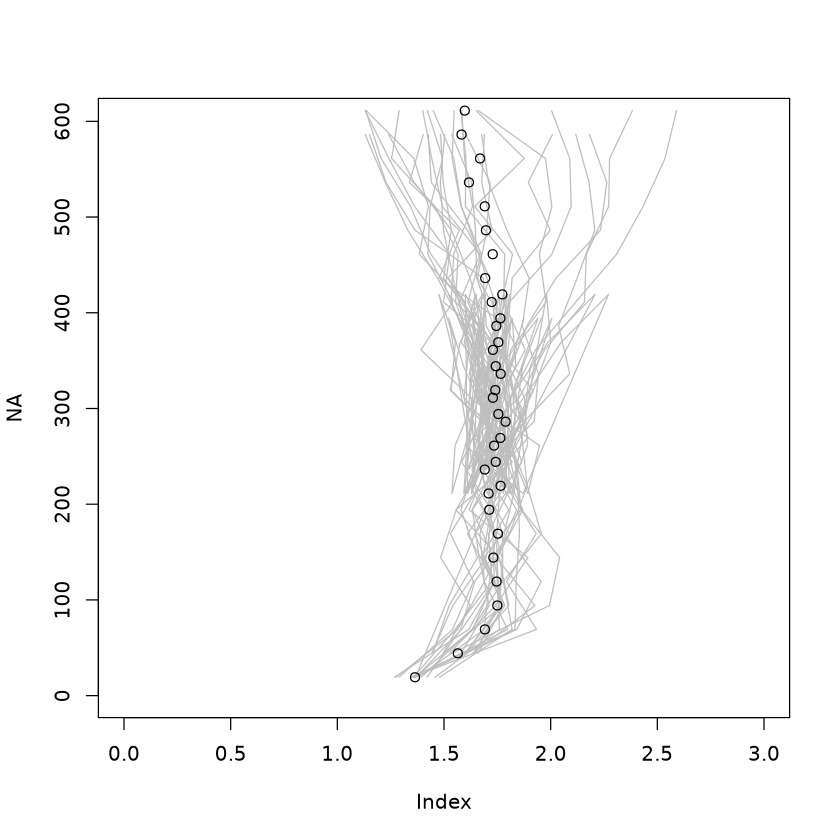

In [3]:
height = unique(data$y)
height

table16 = data[data$y == height[3],c(2, 4)]
table18 = data[data$y == height[2],c(2, 4)]
length(table18$z)

for (i in 4:length(height)) {
  plotd = data[data$y == height[i],4]
  if(length(plotd)==16){table16 = cbind(table16, plotd)}
  if(length(plotd)==18){table18 = cbind(table18, plotd)}
}

t16 = cbind(table16[1], rowMeans(table16[-1]))
colnames(t16) = c("z", "Urms")

t18 = cbind(table18[1], rowMeans(table18[-1]))
colnames(t18) = c("z", "Urms")


table = rbind(t16, t18)

tableRMS = table[order(table$z, decreasing = FALSE), ]

plot(NA, xlim = c(0, 3), ylim = c(1,600))
for (i in 1:length(height)) {
  plotd = data #[order(data1$y),]
  plotd = plotd[plotd$y == height[i],]
  lines(plotd$Urms, plotd$z, col = "grey")
}
points(tableRMS$Urms, tableMean$z)

In [13]:
zref = 200

fm <- nls(Umean ~ a*(z/zref)^b, 
          tableMean, 
          start = list(a = 7, b = 0.2))

Uref = fm$m$getPars()[1]

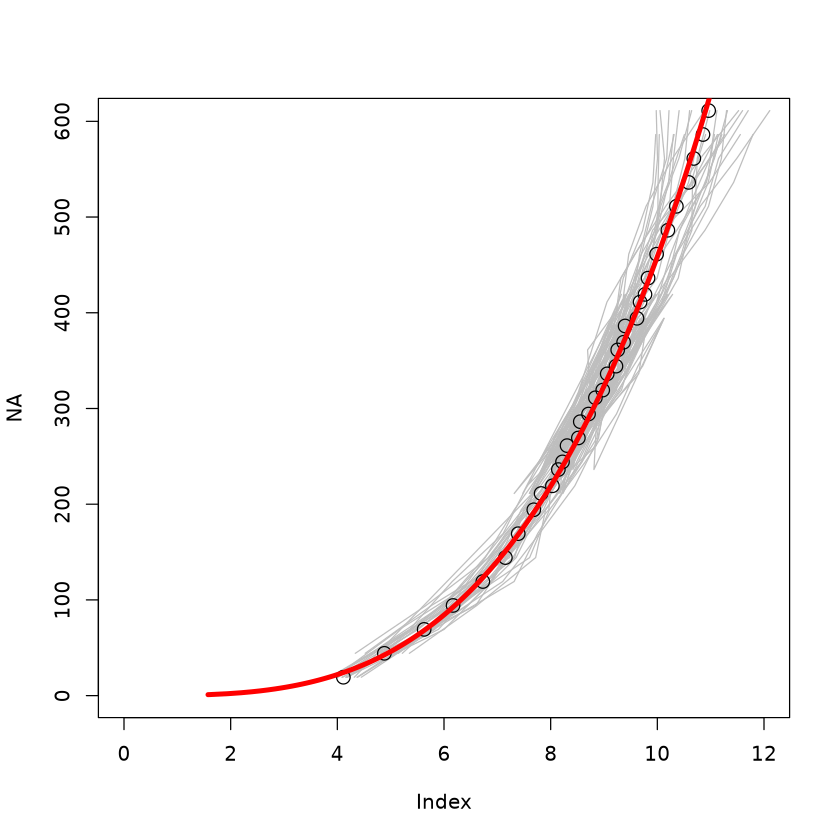

In [22]:
z = seq(1,1000, len = 1000)
plot(NA, xlim = c(0, 12), ylim = c(1,600), cex =2, pch = 2)
for (i in 1:length(height)) {
  plotd = data #[order(data1$y),]
  plotd = plotd[plotd$y == height[i],]
  lines(plotd$Umean, plotd$z, col = "grey")
}
points(tableMean$Umean, tableMean$z, col = "black", cex =1.5, pch =1)
Unorm = Uref*(z/zref)^fm$m$getPars()[2]
lines(Unorm, z, col = "red", lwd = 4)

    Unorm 
0.9596725 
(Intercept) 
   6.415484 
     xfit 
0.9149907 
(Intercept) 
   5.263381 


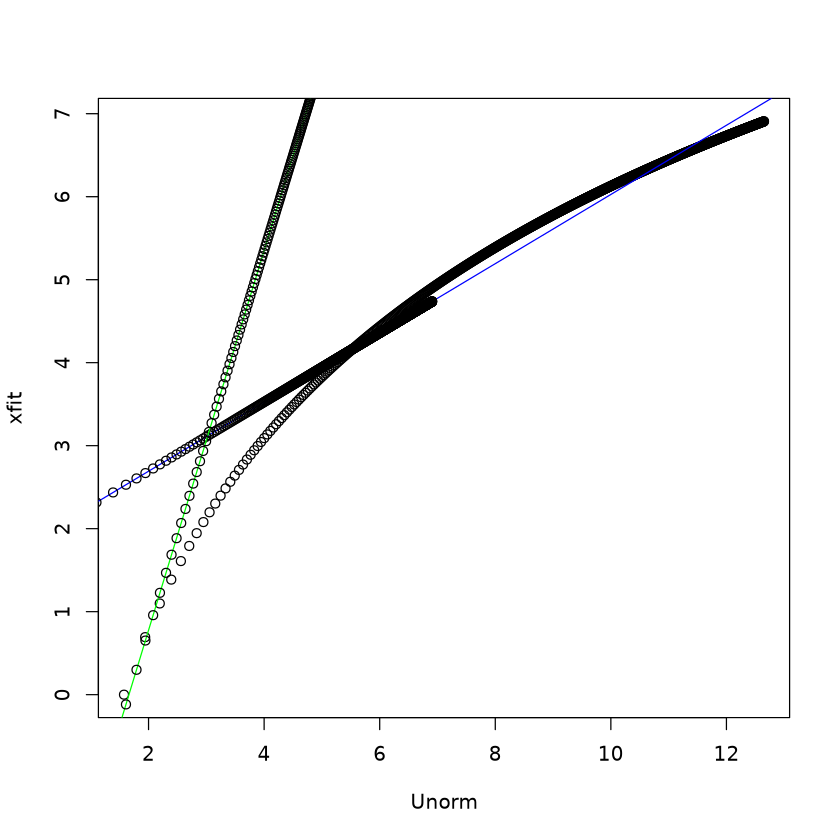

In [24]:
xfit = log(z)
plot(Unorm, xfit)

model = lm(xfit~Unorm); summary(model); coef(model)
abline(coef(model)[1], coef(model)[2], col = "blue")
points(xfit, coef(model)[1] + coef(model)[2]*xfit)
ustar = 0.4/coef(model)[2]
z0 = exp(coef(model)[1])
print(ustar);print(z0)

model2 = lm(Unorm~xfit); summary(model2); coef(model2)
abline(coef(model2)[1], coef(model2)[2], col = "green")
points(xfit, coef(model2)[1] + coef(model2)[2]*xfit)
ustar2 = coef(model2)[2]*0.4
z02 = exp(-coef(model2)[1]/coef(model2)[2])
print(ustar2);print(z02)

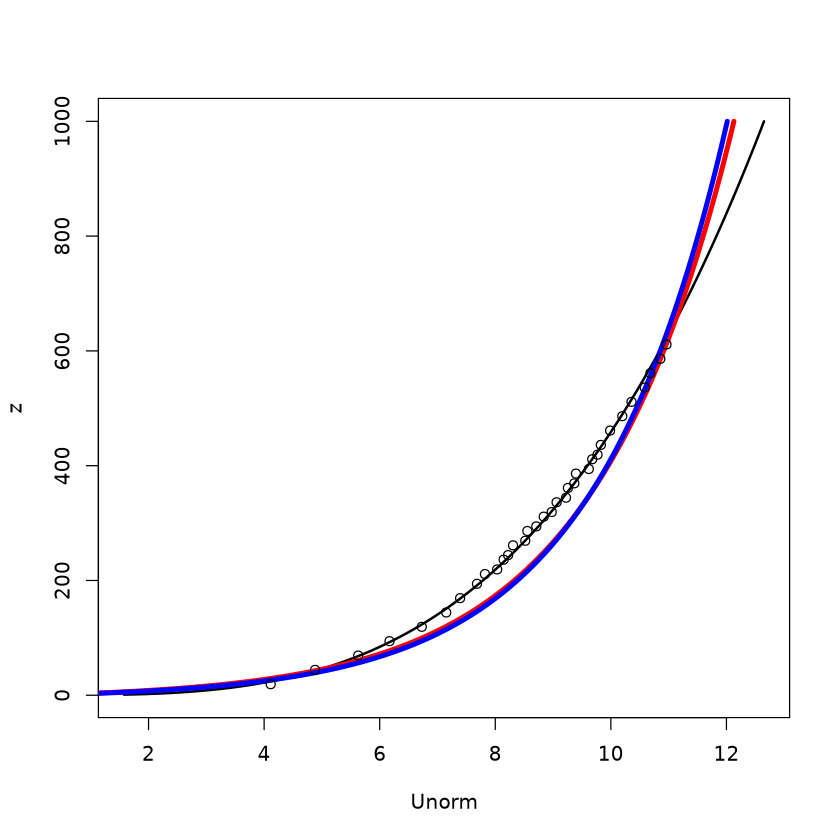

In [28]:
plot(Unorm, z, type = "l", lwd = 2)
lines((ustar/0.4)*log((z+z0)/z0), z, col = "red", lwd = 4)
lines((ustar2/0.4)*log((z+z02)/z02), z, col = "blue", lwd = 4)
points(tableMean$Umean, tableMean$z)

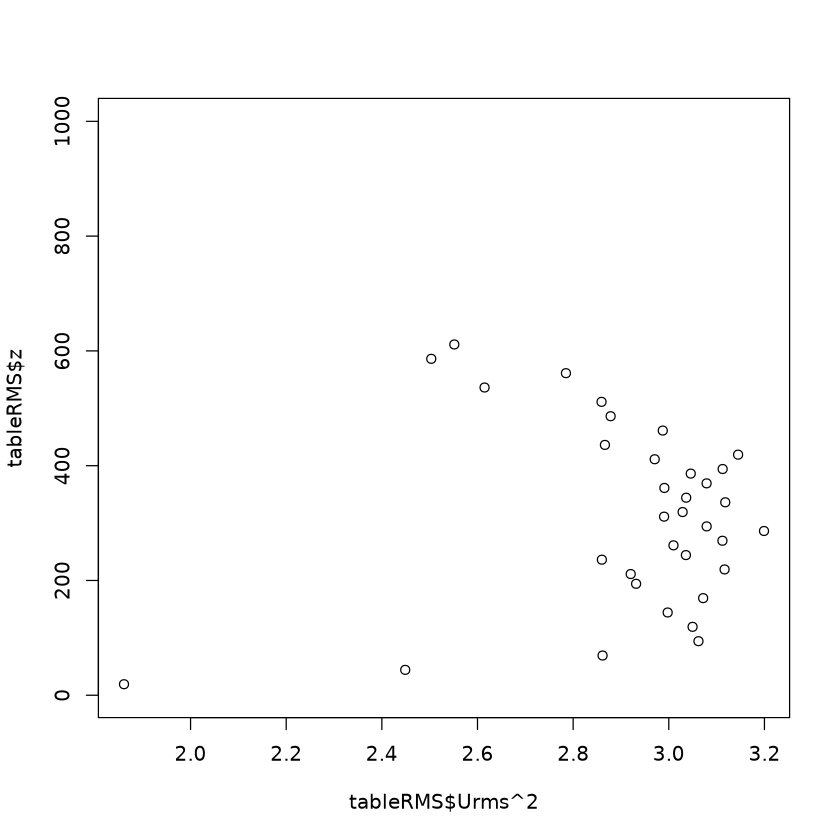

In [29]:
plot(tableRMS$Urms^2, tableRMS$z, ylim = c(1,1000))